# 03 · What really determines QIP performance? Controlled-experiment analysis

**Phase A3: evaluation.** This notebook loads the measured results produced by

```bash
python -m qipbench run      # OFAT sweeps + 2^7 factorial + QHED study
```

It then answers the research question with effect sizes rather than anecdotes.

In [1]:
import sys, numpy as np, matplotlib.pyplot as plt
sys.path.insert(0, "..")
np.set_printoptions(precision=4, suppress=True)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": False})
import pandas as pd, json
from pathlib import Path
from IPython.display import Image, Markdown, display
R = Path("../results")
summary = json.loads((R / "summary.json").read_text())
ofat = pd.read_csv(R / "ofat.csv"); fact = pd.read_csv(R / "factorial.csv")
print(f"{len(ofat)} OFAT runs, {len(fact)} factorial runs")

858 OFAT runs, 1536 factorial runs


## 1. Factor ranking per performance dimension (2⁷ factorial, % of variance explained)

In [2]:
rows = []
for enc, dims in summary["rankings"].items():
    for dim in ("quality", "efficiency", "reliability", "runtime"):
        for rank, f in enumerate(dims[dim][:4], 1):
            rows.append({"encoding": enc, "dimension": dim, "rank": rank, "factor": f["label"],
                         "% variance": f["contribution"], "significant": f["p_value"] < 0.05})
pd.DataFrame(rows).pivot_table(index=["dimension", "rank"], columns="encoding", values="factor", aggfunc="first")

encoding                             frqi                     neqr
dimension   rank                                                  
efficiency  1           Circuit structure               Image size
            2                  Image size      Intensity bit depth
            3         Intensity bit depth        Circuit structure
            4     Transpiler optimisation  Transpiler optimisation
quality     1              Hardware noise               Image size
            2           Measurement shots        Measurement shots
            3                  Image size           Hardware noise
            4           Circuit structure      Intensity bit depth
reliability 1                  Image size           Hardware noise
            2              Hardware noise               Image size
            3           Measurement shots        Measurement shots
            4         Intensity bit depth      Intensity bit depth
runtime     1           Circuit structure               Image size
            2                  Image size           Hardware noise
            3              Hardware noise      Intensity bit depth
            4           Measurement shots        Measurement shots

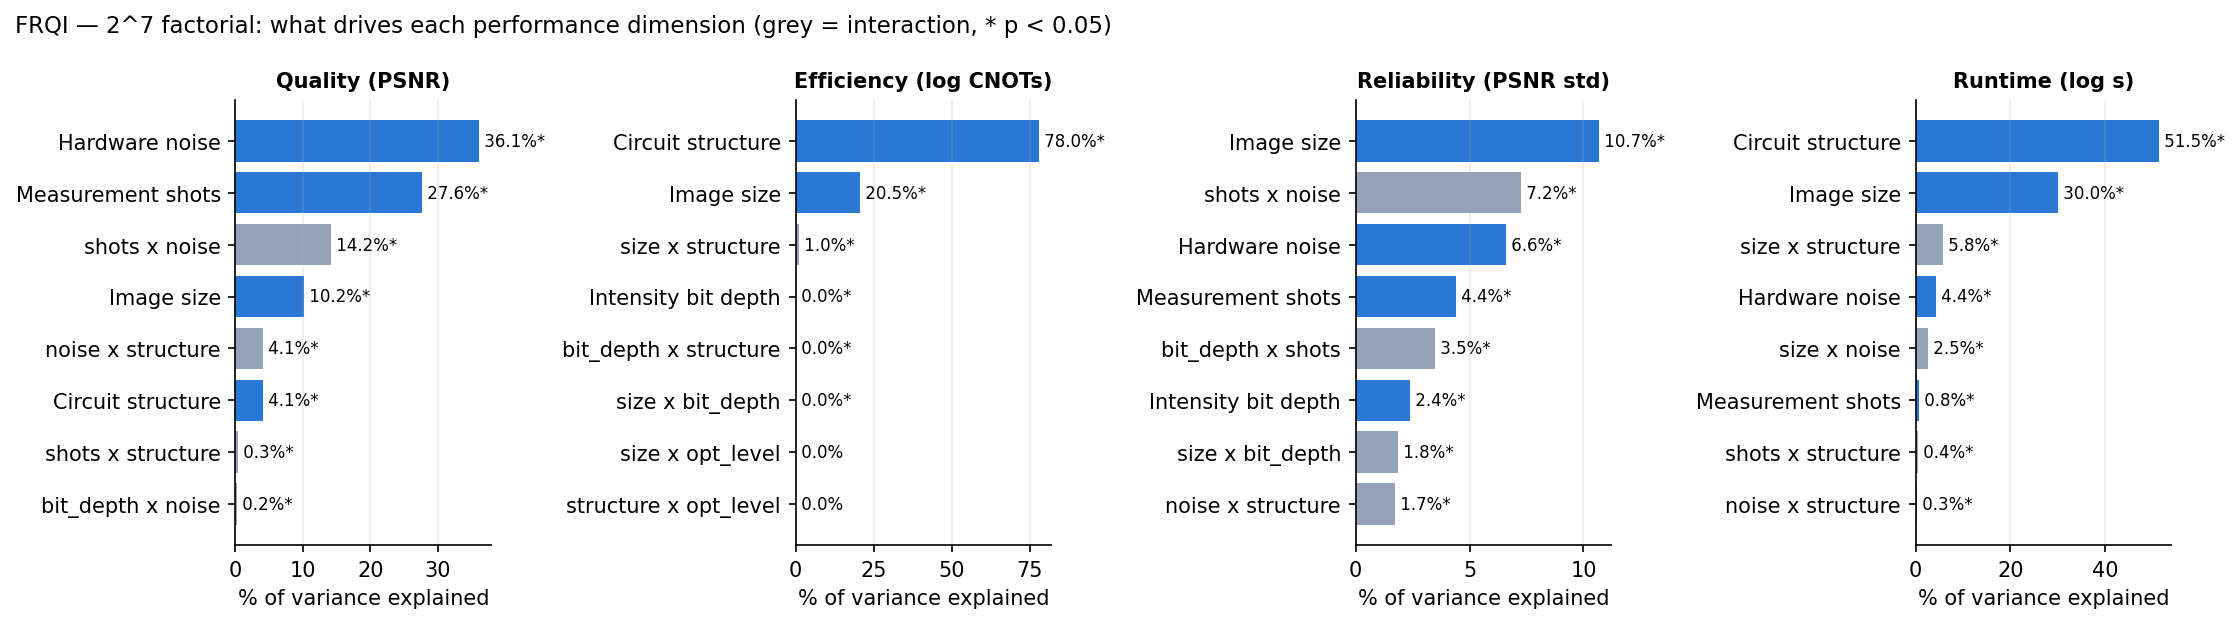

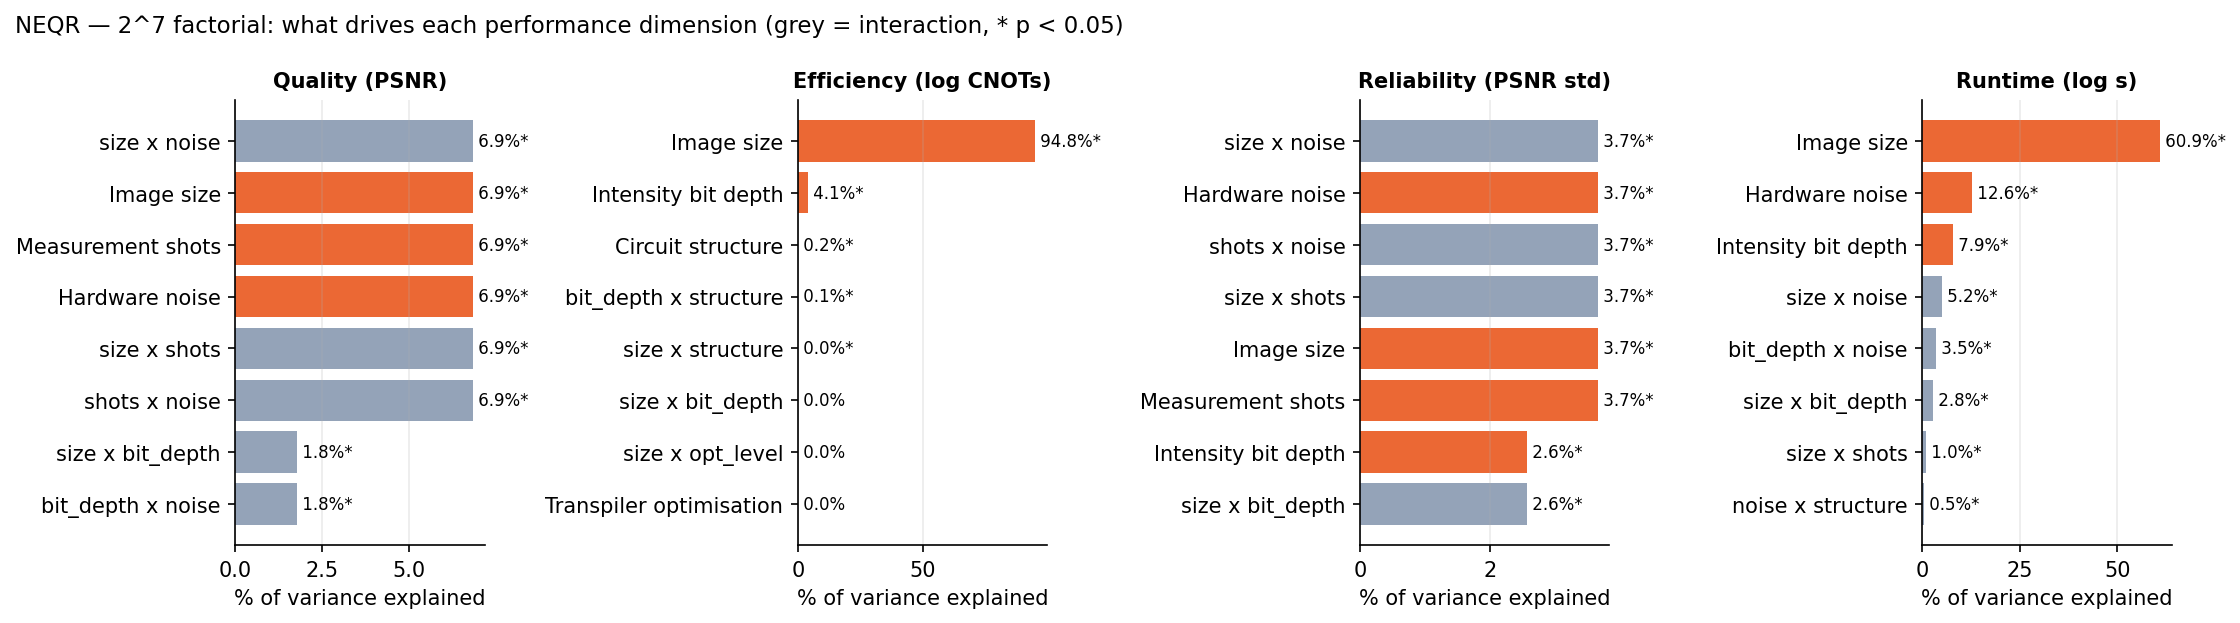

In [3]:
display(Image(R / "figures/factorial_pareto_frqi.png")); display(Image(R / "figures/factorial_pareto_neqr.png"))

## 2. Interactions: noise changes which other factors matter

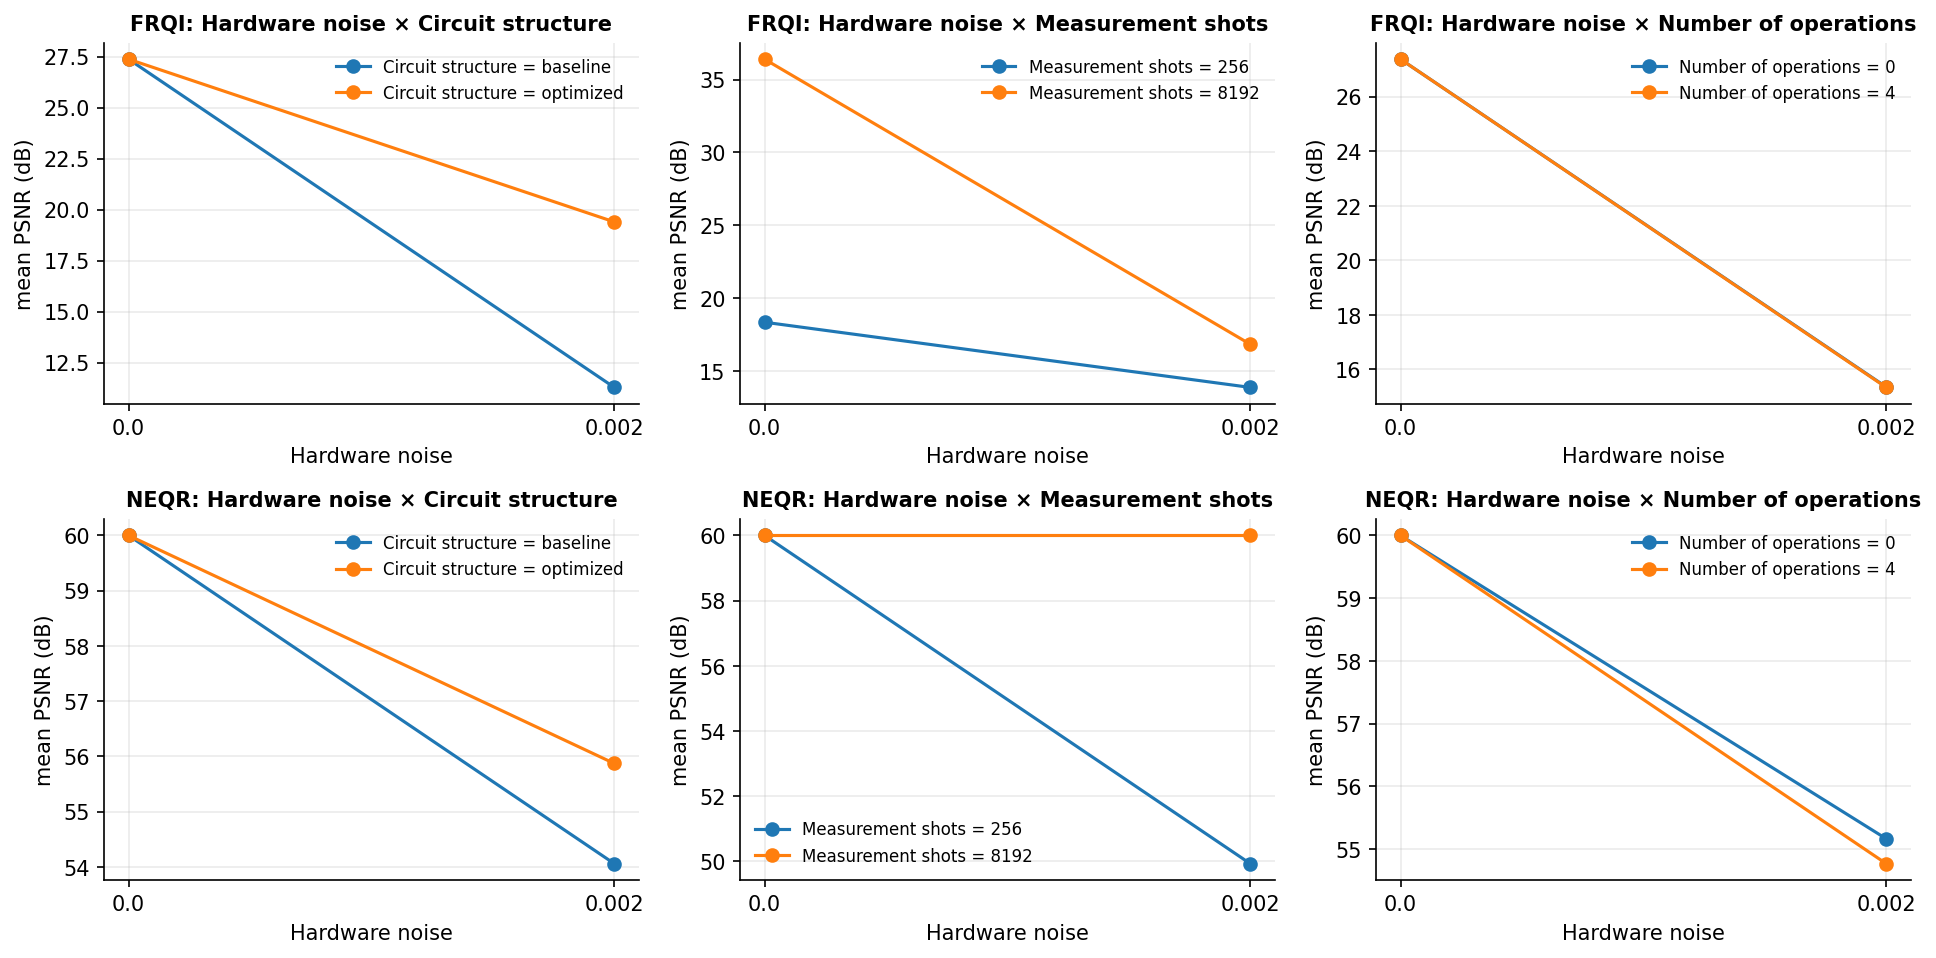

In [4]:
display(Image(R / "figures/factorial_interactions.png"))

## 3. Response curves (one factor at a time)

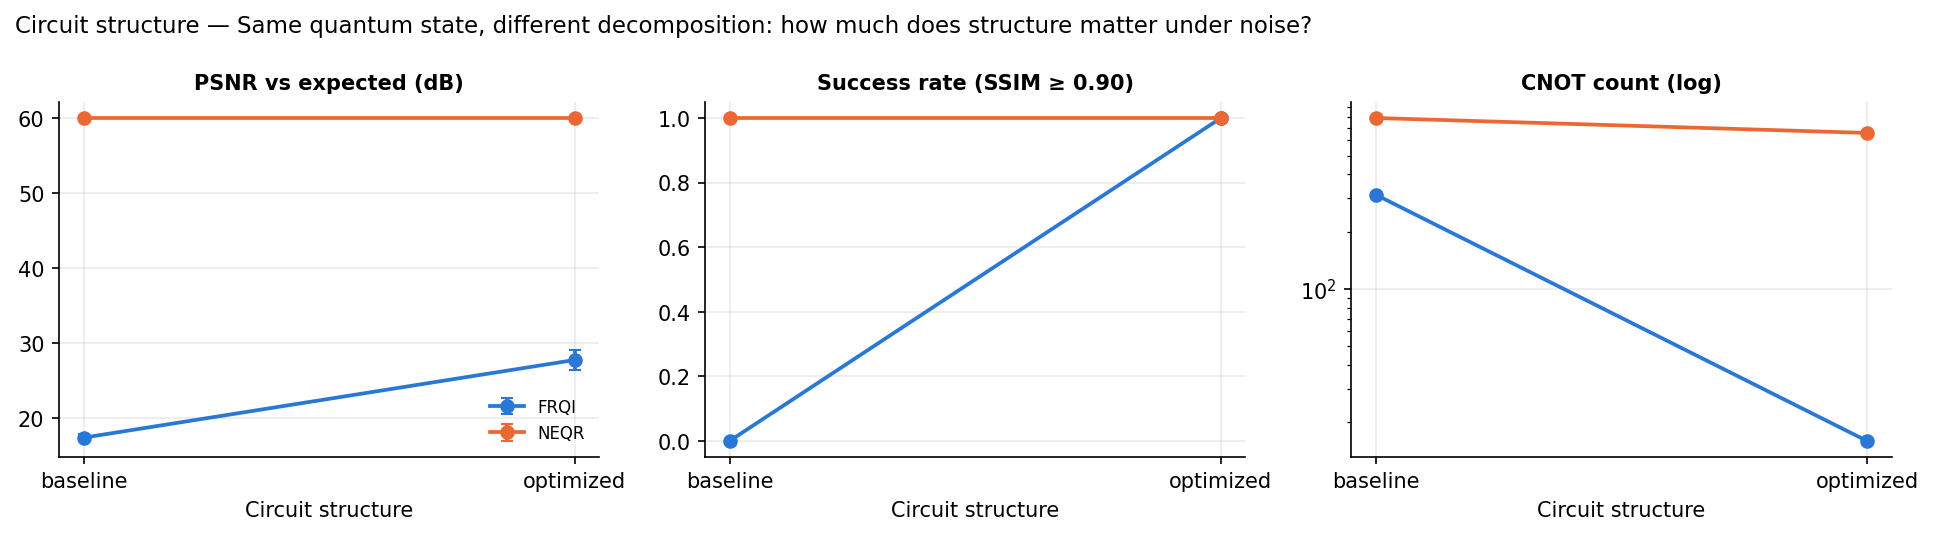

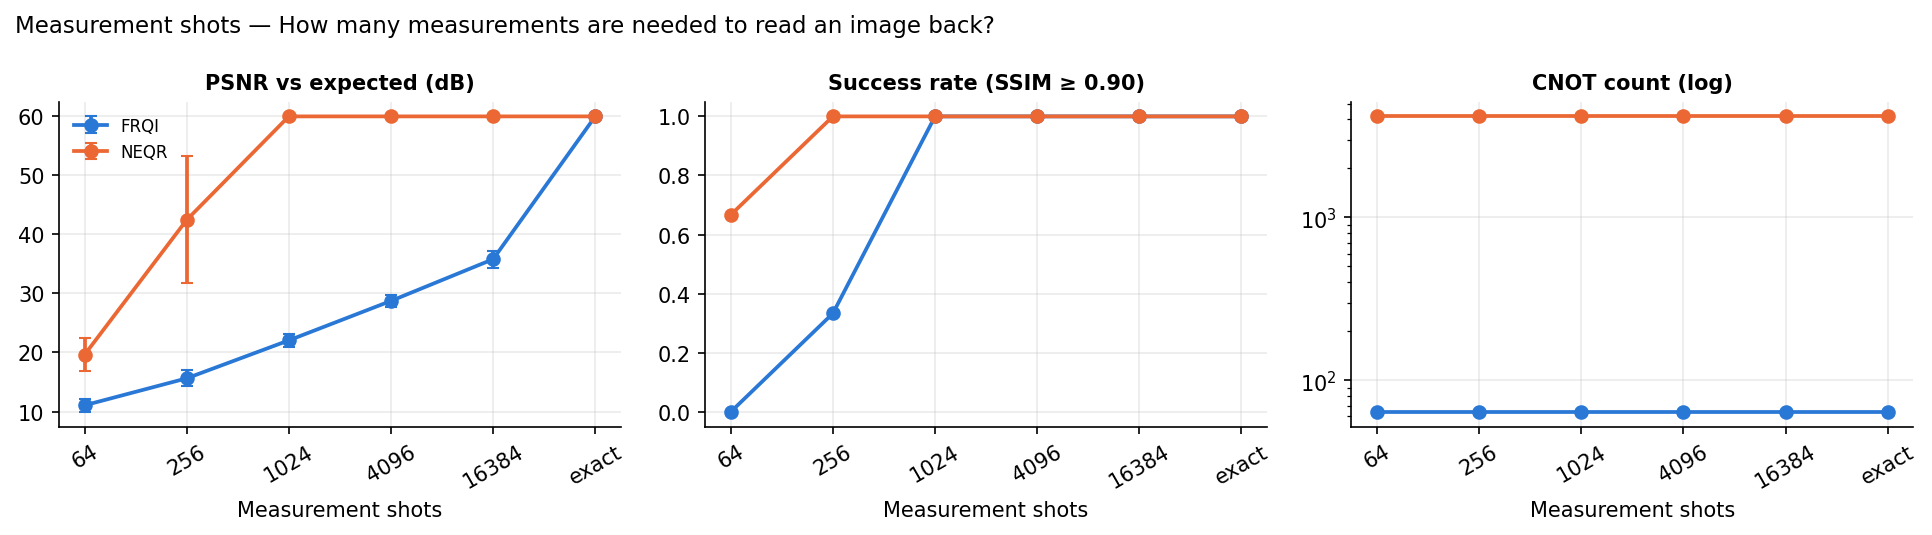

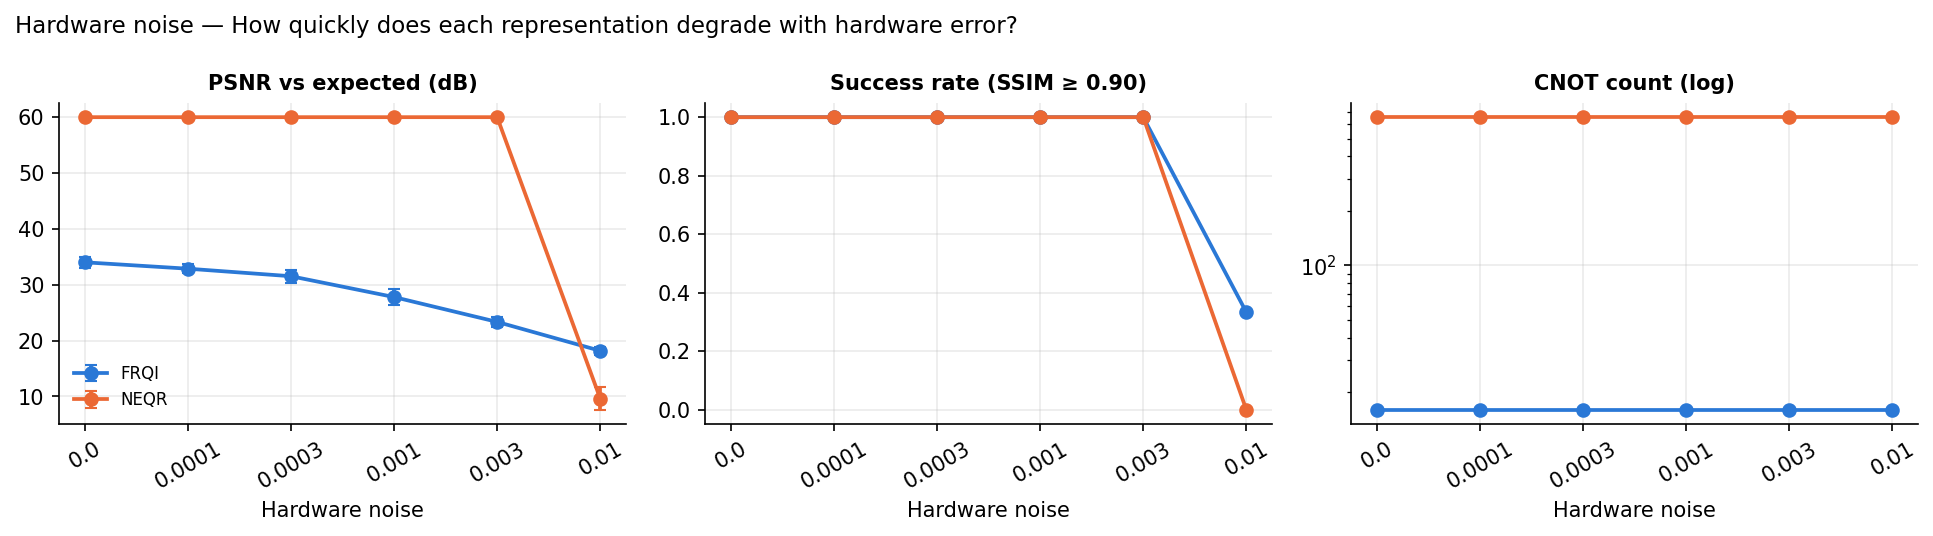

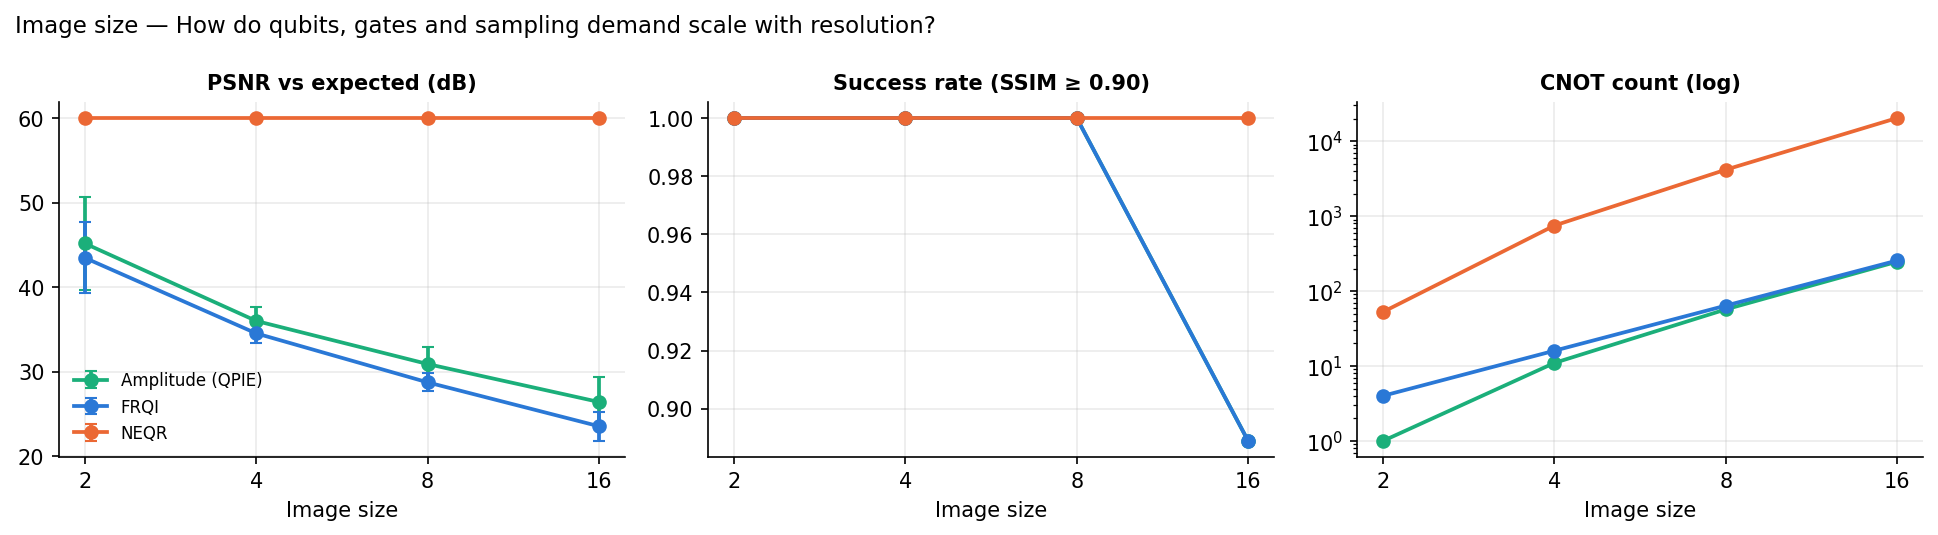

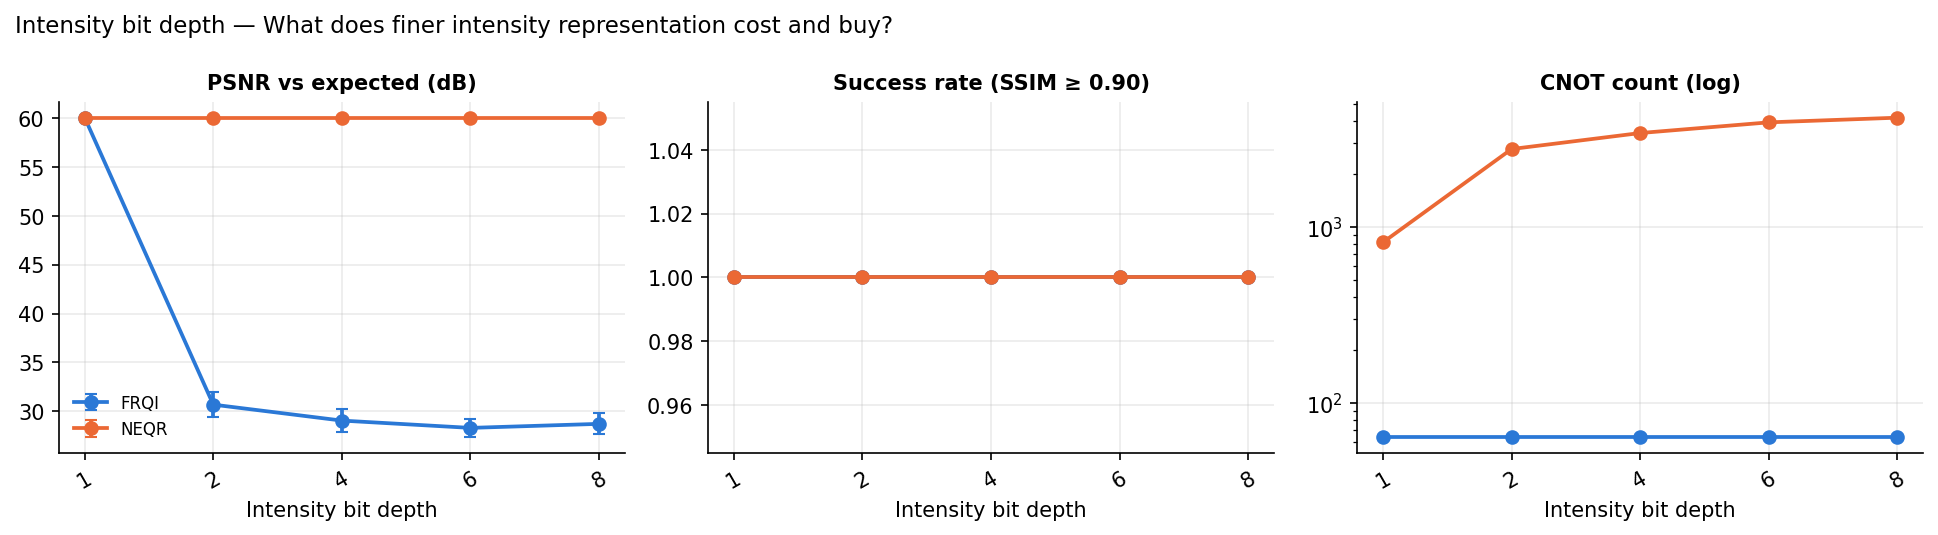

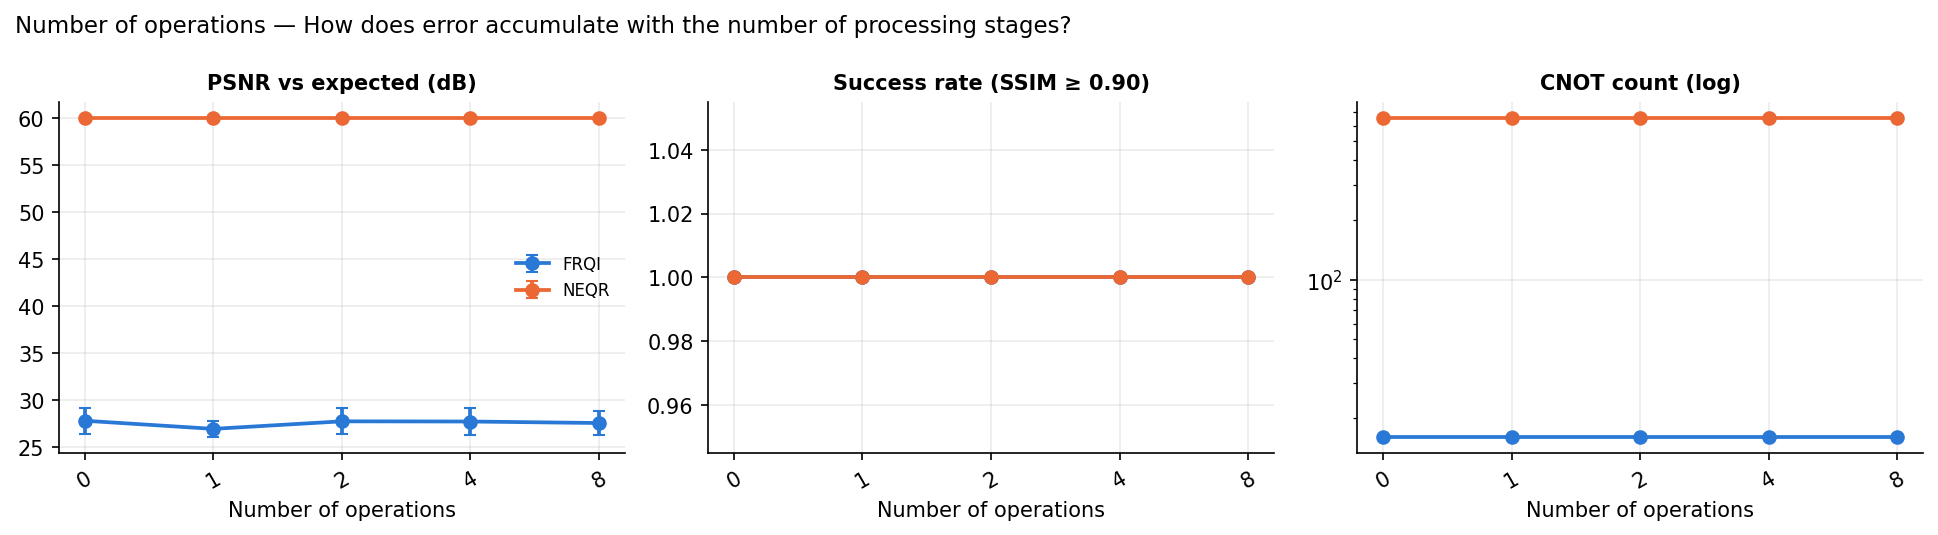

In [5]:
for s in ["structure", "shots", "noise", "image_size", "bit_depth", "operations"]:
    display(Image(R / f"figures/ofat_{s}.png"))

## 4. Influence heat-map: η² of every factor on every dimension

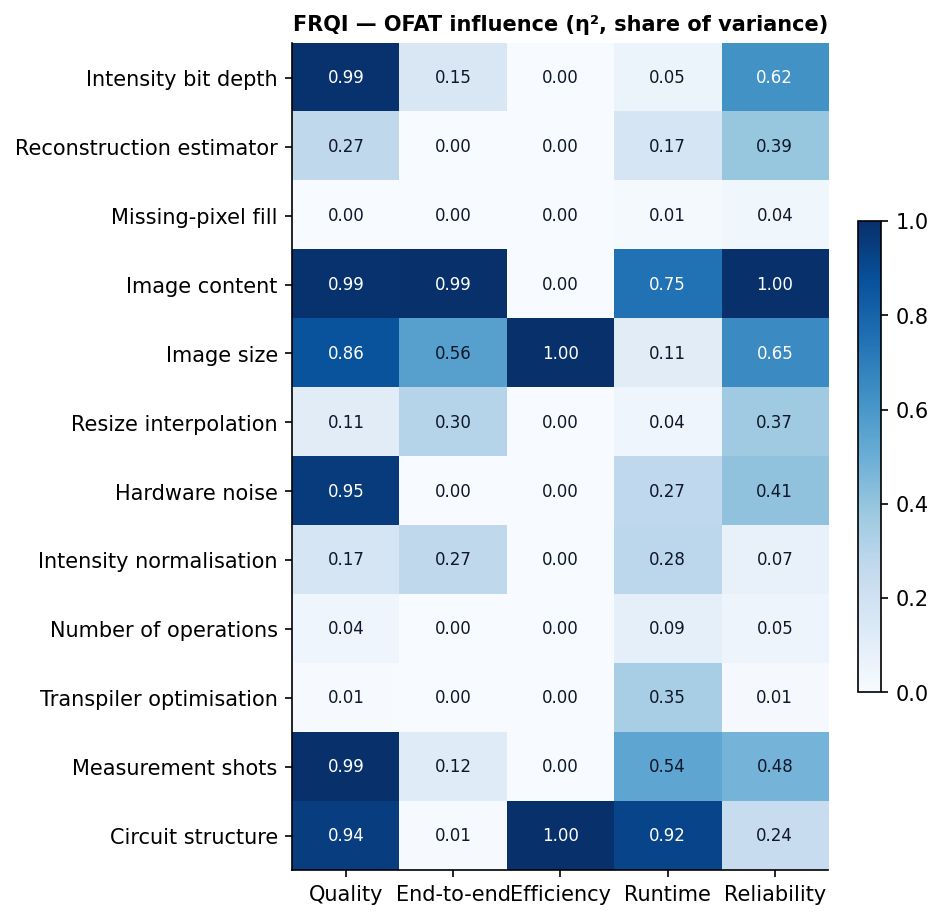

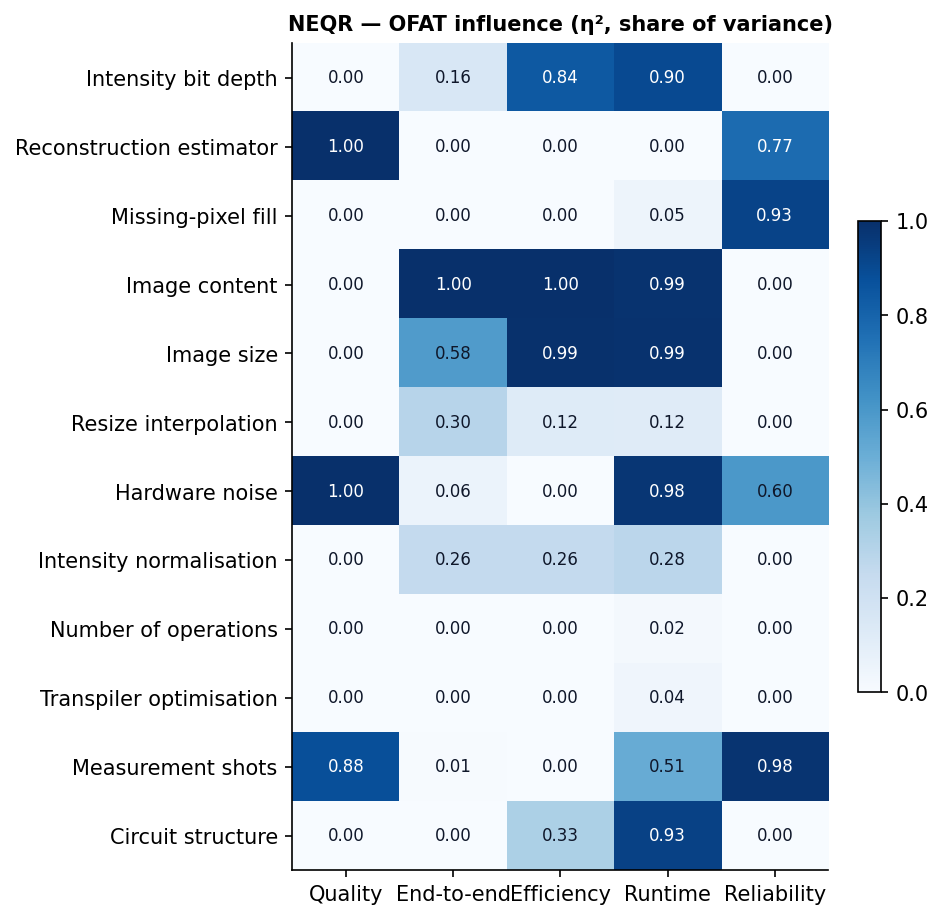

In [6]:
display(Image(R / "figures/influence_heatmap_frqi.png")); display(Image(R / "figures/influence_heatmap_neqr.png"))

## 5. Generated findings

In [7]:
text = (R / "REPORT.md").read_text(encoding="utf-8")
display(Markdown(text.split("## 3.")[0]))

# What Really Determines the Performance of a Quantum Image Processing System?

_Auto-generated by `python -m qipbench report` on 29 Oct 2026 from the measured data in this folder. Every number below is reproducible with `python -m qipbench run`._

## 1. Answer: what really determines performance

Share of variance explained (main effects, 2^7 full factorial, `*` = significant at p < 0.05):

| Dimension | FRQI — top 3 factors | NEQR — top 3 factors |
|---|---|---|
| Quality (PSNR) | Hardware noise 36%*; Measurement shots 28%*; Image size 10%* | Image size 7%*; Measurement shots 7%*; Hardware noise 7%* |
| Efficiency (CNOT count) | Circuit structure 78%*; Image size 21%*; Intensity bit depth 0%* | Image size 95%*; Intensity bit depth 4%*; Circuit structure 0%* |
| Reliability (PSNR spread) | Image size 11%*; Hardware noise 7%*; Measurement shots 4%* | Hardware noise 4%*; Image size 4%*; Measurement shots 4%* |
| Runtime | Circuit structure 51%*; Image size 30%*; Hardware noise 4%* | Image size 61%*; Hardware noise 13%*; Intensity bit depth 8%* |

How the variance splits (main effects / two-factor interactions / higher-order + replicate noise):

- **FRQI:** Quality 78 / 19 / 3 %, Efficiency 98 / 1 / 0 %, Reliability 26 / 17 / 57 %, Runtime 87 / 10 / 4 %
- **NEQR:** Quality 23 / 27 / 50 %, Efficiency 99 / 0 / 1 %, Reliability 14 / 20 / 66 %, Runtime 82 / 14 / 4 %

A large interaction or higher-order share means the factor's influence depends on the other factors: performance there is a *regime* (a cliff), not a sum of independent knobs.

Strongest interactions (factors that amplify each other):

- **FRQI / Quality (PSNR):** shots × noise (14.2%), noise × structure (4.1%)
- **FRQI / Reliability (PSNR spread):** shots × noise (7.2%), bit_depth × shots (3.5%)
- **NEQR / Quality (PSNR):** size × noise (6.9%), size × shots (6.9%)
- **NEQR / Reliability (PSNR spread):** size × noise (3.6%), shots × noise (3.6%)

## 2. Key findings

1. **Circuit structure is the largest lever on cost.** For a 4×4 image the Gray-code FRQI needs 16 CNOTs versus 312 for the naive multi-controlled version, and under p = 0.001 noise PSNR rises from 17.4 dB to 27.8 dB — the same quantum state, different engineering.
2. **FRQI quality is shot-limited, NEQR quality is coverage-limited.** At 8×8, FRQI PSNR goes from 11.0 dB (64 shots) to 35.8 dB (16 384 shots); NEQR is exact as soon as every pixel is observed (coverage 0.67 at 64 shots → 1.00 at 1 024).
3. **NEQR trades qubits and gates for noise robustness.** At p = 1e-3 NEQR keeps 60.0 dB (majority vote absorbs bit-flips) while FRQI falls to 27.8 dB; at p = 1e-2 the values are 9.6 dB vs 18.2 dB. NEQR pays 41× more CNOTs.
4. **Bit depth is free for FRQI but linear in qubits for NEQR.** FRQI stays at 7 qubits for any depth; NEQR grows from 8 (1 bit) to 15 qubits (8 bit).
5. **Resolution dominates end-to-end quality, not the quantum channel.** End-to-end PSNR against the source improves from 8.7 dB (2×2) to 17.0 dB (16×16) for FRQI with exact-quality encoding, but at a fixed 4 096 shots FRQI channel PSNR drops to 23.5 dB at 16×16 because shots per pixel fall.
6. **Pre-processing matters at the edges of the pipeline.** Interpolation moves end-to-end PSNR by 3.4 dB; histogram equalisation lowers end-to-end PSNR (10.8 dB vs 13.9 dB with min-max) because it changes the intensities on purpose.
7. **Operations are cheap compared with state preparation.** Eight inversion stages change FRQI PSNR by 0.24 dB: a pixel-wise operator is one layer, while loading the image costs hundreds of gates.
8. **The reconstruction estimator is a free accuracy gain.** The FRQI conditional estimator reaches 27.8 dB vs 25.5 dB for the marginal one on the same measurements; NEQR majority vote reaches 60.0 dB vs 20.9 dB for the mean.
9. **Quantum edge detection (QHED) is exact in the infinite-shot limit** (F1 = 1.00) and needs many shots on realistic images: F1 = 0.34 at 256 shots, 0.92 at 16 384. Low-contrast edges are the first to disappear because their probability scales with the squared difference.

